In [1]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Disaster management/Global_Landslide.csv", low_memory=False)


In [2]:
#previwing to check the data arrangement
print("--- DISCOVERING NASA CATALOG COLUMNS ---")
print(list(df.columns))
print("\n--- PREVIEWING THE FIRST 3 ROWS ---")
df.head(3)


--- DISCOVERING NASA CATALOG COLUMNS ---
['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude']

--- PREVIEWING THE FIRST 3 ROWS ---


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,country_code,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,08/01/2008 12:00:00 AM,NaN,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",unknown,landslide,...,CN,Shaanxi,0.0,Jingyang,41.02145,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,107.4500,32.5625
1,Oregonian,http://www.oregonlive.com/news/index.ssf/2009/...,956,01/02/2009 02:00:00 AM,NaN,"Lake Oswego, Oregon",Hours of heavy rain are to blame for an overni...,"Lake Oswego, Oregon",5km,mudslide,...,US,Oregon,36619.0,Lake Oswego,0.60342,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-122.6630,45.4200
2,CBS News,https://www.cbsnews.com/news/dozens-missing-af...,973,01/19/2007 12:00:00 AM,NaN,"San Ramon district, 195 miles northeast of the...",(CBS/AP) At least 10 people died and as many a...,"San Ramon district, 195 miles northeast of the...",10km,landslide,...,PE,Junín,14708.0,San Ramón,0.85548,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,-75.3587,-11.1295


In [3]:
%load_ext google.colab.data_table
df.columns = df.columns.str.strip()
filtered_df = df[df['country_code'].isin(['IN', 'JP', 'India', 'Japan'])]
columns_to_keep = ['latitude', 'longitude', 'country_code']
cleaned_data = filtered_df[columns_to_keep].dropna(subset=['latitude', 'longitude'])
output_path = "/content/drive/MyDrive/Disaster management/cleaned_landslide_hazards_inventory.csv"
cleaned_data.to_csv(output_path, index=False)
print(f"--- FILTERING COMPLETE ---")
print(f"Successfully isolated {len(cleaned_data)} hazard points for India and Japan!")
display(cleaned_data)


--- FILTERING COMPLETE ---
Successfully isolated 1347 hazard points for India and Japan!


,latitude,longitude,country_code
32,26.882600,88.278800,IN
34,26.857200,88.314300,IN
41,34.049600,131.572900,JP
43,34.385200,132.459200,JP
45,27.478000,88.527000,IN
...,...,...,...
9837,27.043571,88.265221,IN
9852,31.488100,76.670200,IN
9859,30.452800,78.104500,IN
9865,10.083800,77.069600,IN


In [4]:
import numpy as np
hazard_presence=cleaned_data.copy()
#assigning labels, 1-->hazardous.....0--->safe
hazard_presence["hazard label"]=1
#separate india and japan rows
india_points = hazard_presence[hazard_presence['country_code'].isin(['IN', 'India'])]
japan_points = hazard_presence[hazard_presence['country_code'].isin(['JP', 'Japan'])]
#create safe points(abscence)
def generate_absence_points(presence_df, country_code, count):
  #boundary coord
  min_lat, max_lat=presence_df["latitude"].min(), presence_df["latitude"].max()
  min_long, max_long=presence_df["longitude"].min(), presence_df["longitude"].max()
  #random coordinate in the boundary
  random_lats=np.random.uniform(min_lat, max_lat, count)
  random_longs = np.random.uniform(min_long, max_long, count)
  absence_df=pd.DataFrame({
        'latitude': random_lats,
        'longitude': random_longs,
        'country_code': country_code,
        'hazard label': 0
    })
  return absence_df
# Generate matching counts of safe points for both regions
india_absence = generate_absence_points(india_points, 'IN', len(india_points))
japan_absence = generate_absence_points(japan_points, 'JP', len(japan_points))
balanced_dataset = pd.concat([hazard_presence, india_absence, japan_absence], ignore_index=True)
output_balanced_path = "/content/drive/MyDrive/Disaster management/balanced_hazards_inventory.csv"
balanced_dataset.to_csv(output_balanced_path, index=False)
print("==============================================")
print("--- HAZARD INVENTORY BALANCED(GROUND TRUTH) ---")
print("==============================================")
print("Real Landslides (Class 1):",{len(hazard_presence)},"points")
print("Generated Safe Zones (Class 0):",{len(india_absence) + len(japan_absence)},"points")
print(f"Total training size for AI: {len(balanced_dataset)} rows")
print("Balanced interactive dataset structure:")
display(balanced_dataset.sample(50))

--- HAZARD INVENTORY BALANCED(GROUND TRUTH) ---
Real Landslides (Class 1): {1347} points
Generated Safe Zones (Class 0): {1347} points
Total training size for AI: 2694 rows
Balanced interactive dataset structure:


,latitude,longitude,country_code,hazard label
1707,19.036975,73.179345,IN,0
659,25.133300,93.966700,IN,1
2121,30.721321,73.363103,IN,0
930,27.575400,91.975400,IN,1
237,15.949000,73.966700,IN,1
788,33.028900,74.948900,IN,1
1887,18.012737,78.052060,IN,0
2398,15.058801,74.363941,IN,0
1634,21.392296,87.486135,IN,0
1465,32.258405,85.955498,IN,0


In [5]:
#google earth initialize
import ee
from google.colab import auth

print("Starting Cloud Authentication flow...")
# Open Google Account permissions pop-up
auth.authenticate_user()

# Link directly to your project ID
YOUR_PROJECT_ID = 'named-standard-515615-q0'

try:
    ee.Initialize(project=YOUR_PROJECT_ID)
    print("SUCCESS: Google Earth Engine initialized successfully with your project ID!")
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project=YOUR_PROJECT_ID)
    print("SUCCESS: Google Earth Engine authenticated and initialized!")

Starting Cloud Authentication flow...
SUCCESS: Google Earth Engine initialized successfully with your project ID!


In [6]:
import os
#Look for signed coordinates variable in Colab memory
if 'balanced_dataset' in locals():
    df_balanced = balanced_dataset.copy()
    print("Successfully found your signed coordinates table in memory.")
else:
    # If memory cleared, load it from your Google Drive save file
    path_options = [
        "/content/drive/MyDrive/Disaster management/balanced_hazards_inventory.csv",
        "/content/drive/MyDrive/Disaster_Management/balanced_hazards_inventory.csv"
    ]
    chosen_path = next((p for p in path_options if os.path.exists(p)), None)
    if chosen_path is None:
        raise FileNotFoundError("Could not find your balanced coordinates. Please run your balancing cell first!")
    df_balanced = pd.read_csv(chosen_path)
    print(f"Loaded {len(df_balanced)} coordinates from your Google Drive.")

#Fetch Copernicus Collection And Flatten Into A Single Mosaic Image
dem_collection = ee.ImageCollection('COPERNICUS/DEM/GLO30_2024_1').select('DEM')
#native projection
native_projection=dem_collection.first().projection()
#mosaic and projection restore
dem = dem_collection.mosaic().setDefaultProjection(native_projection) # Converted from Collection to single Image map

#Calculate Terrain Slope Angle from the single mosaic image
slope_layer = ee.Terrain.slope(dem)
terrain_stack = dem.addBands(slope_layer)
#Format coordinates into cloud features
print("Extracting satellite metrics from cloud layers... (Please wait 1 minute)")
ee_features = []
for index, row in df_balanced.iterrows():
    geom = ee.Geometry.Point([row['longitude'], row['latitude']])
    feat = ee.Feature(geom, {'row_id': index})
    ee_features.append(feat)
fc_points = ee.FeatureCollection(ee_features)
#Pull spatial values from GEE
sampled_data = terrain_stack.sampleRegions(
    collection=fc_points,
    properties=['row_id'],
    scale=30
).getInfo()
print("Satellite terrain data retrieved successfully!")

#Map physical features back to table
elevation_mapping = {}
slope_mapping = {}
for feature in sampled_data['features']:
    props = feature['properties']
    r_id = props['row_id']
    elevation_mapping[r_id] = props.get('DEM', None)
    slope_mapping[r_id] = props.get('slope', None)
df_balanced['elevation'] = df_balanced.index.map(elevation_mapping)
df_balanced['slope'] = df_balanced.index.map(slope_mapping)
df_balanced = df_balanced.dropna(subset=['elevation', 'slope'])

#Filter out unstable safe points (Slope > 5 degrees)
initial_count = len(df_balanced)
bad_safe_zones_mask = (df_balanced['hazard label'] == 0) & (df_balanced['slope'] >=10)
df_cleaned_physics = df_balanced[~bad_safe_zones_mask].copy()

final_count = len(df_cleaned_physics)
dropped_count = initial_count - final_count
#Save verified dataset back to permanent Google Drive folder
parent_folder = "/content/drive/MyDrive/Disaster management"
if not os.path.exists(parent_folder):
    os.makedirs(parent_folder)
output_physics_path = os.path.join(parent_folder, "hazards_with_true_physics.csv")
df_cleaned_physics.to_csv(output_physics_path, index=False)
print("==============================================")
print("TERRAIN PROCESSING COMPLETE")
print("==============================================")
print(f"Dropped {dropped_count} unstable safe points from your data matrix.")
print(f"Total physically verified rows remaining for AI training: {final_count}")
print("Your updated physics-based data matrix:")

# Display the interactive grid
display(df_cleaned_physics.head(2000))


Successfully found your signed coordinates table in memory.
Extracting satellite metrics from cloud layers... (Please wait 1 minute)
Satellite terrain data retrieved successfully!
TERRAIN PROCESSING COMPLETE
Dropped 264 unstable safe points from your data matrix.
Total physically verified rows remaining for AI training: 2067
Your updated physics-based data matrix:


,latitude,longitude,country_code,hazard label,elevation,slope
0,26.882600,88.278800,IN,1,1546.905640,17.963409
1,26.857200,88.314300,IN,1,1077.673096,14.833567
2,34.049600,131.572900,JP,1,10.374061,0.258799
3,34.385200,132.459200,JP,1,6.502405,4.959507
4,27.478000,88.527000,IN,1,765.601196,33.432098
...,...,...,...,...,...,...
2557,27.023814,85.154734,IN,0,96.377174,0.611616
2560,24.481083,78.471848,IN,0,410.272430,0.801772
2561,20.569685,75.877221,IN,0,421.364990,7.292979
2564,33.121202,90.092967,IN,0,4960.972656,1.023692


In [ ]:
#Data summary... the data is unbalanced later we will use balance weight
print("--- DATA SUMMARY ---")
print(df_cleaned_physics.info())

print("\n--- NULL VALUES ---")
print(df_cleaned_physics.isnull().sum())

print("\n--- CLASS BALANCE ---")
print(df_cleaned_physics['hazard label'].value_counts())

print("\n--- BASIC STATS ---")
print(df_cleaned_physics.describe())

--- DATA SUMMARY ---
<class 'pandas.core.frame.DataFrame'>
Index: 2056 entries, 0 to 2693
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   latitude      2056 non-null   float64
 1   longitude     2056 non-null   float64
 2   country_code  2056 non-null   object 
 3   hazard label  2056 non-null   int64  
 4   elevation     2056 non-null   float64
 5   slope         2056 non-null   float64
dtypes: float64(4), int64(1), object(1)
memory usage: 112.4+ KB
None

--- NULL VALUES ---
latitude        0
longitude       0
country_code    0
hazard label    0
elevation       0
slope           0
dtype: int64

--- CLASS BALANCE ---
hazard label
1    1347
0     709
Name: count, dtype: int64

--- BASIC STATS ---
          latitude    longitude  hazard label    elevation        slope
count  2056.000000  2056.000000   2056.000000  2056.000000  2056.000000
mean     25.653741    85.456930      0.655156  1082.522191    13.624972
std 

In [7]:
import ee
import pandas as pd

#RAINFALL (CHIRPS) - Average monthly precipitation over the last 5 years
# This captures the general climate (monsoons in India, typhoons in Japan)
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').filterDate('2019-01-01', '2024-01-01') \
    .select('precipitation')

# Sum all daily rain, then divide by 60 months to get the average monthly rain
rainfall = chirps.sum().divide(60).rename('rainfall')

# 2. VEGETATION (NDVI from MODIS) - 3-year median
modis = ee.ImageCollection('MODIS/061/MOD13A2').filterDate('2021-01-01', '2024-01-01') \
    .select('NDVI')

# Scale factor for MODIS NDVI is 0.0001
ndvi = modis.median().multiply(0.0001).rename('NDVI')

# COMBINE EVERYTHING
# Forcing the rainfall and NDVI to match the exact projection of opernicus DEM
full_feature_stack = terrain_stack.addBands([
    rainfall.setDefaultProjection(dem.projection()),
    ndvi.setDefaultProjection(dem.projection())
])

In [8]:
import ee

#Convert list to FeatureCollection
features_fc = ee.FeatureCollection(ee_features)

#Sample the new stack
sampled_data = full_feature_stack.sampleRegions(
    collection=features_fc,
    scale=30,
    geometries=False
)

#EXPORT TO GOOGLE DRIVE
task = ee.batch.Export.table.toDrive(
    collection=sampled_data,
    description='Landslide_Features_Export',
    folder='Disaster management',
    fileNamePrefix='landslide_data_',
    fileFormat='CSV'
)

task.start()
print("Export task started successfully!")
print("Check your 'Disaster management' folder in Google Drive.")

Export task started successfully!
Check your 'Disaster management' folder in Google Drive.


In [9]:
import pandas as pd
from google.colab import drive

# Load the CSV from folder
file_path = '/content/drive/MyDrive/Disaster management/landslide_data_.csv'
df_gee_full = pd.read_csv(file_path)

# Merge with specific table
df_NDVI = df_cleaned_physics.merge(df_gee_full, left_index=True, right_on='row_id')

# Print columns to verify what got duplicated
print("--- COLUMNS BEFORE CLEANING ---")
print(df_NDVI.columns.tolist())

# Drop the old slope_x column
if 'slope_x' in df_NDVI.columns:
    df_final = df_NDVI.drop(columns=['slope_x'])
    print("Dropped the old 'slope_x' column.")

# Set up the correct column names for null dropping
cols_to_dropna = ['DEM', 'slope_y', 'rainfall', 'NDVI']

# Check if DEM also got duplicated (DEM_x, DEM_y). If so, update the list.
if 'DEM_y' in df_NDVI.columns:
    cols_to_dropna[0] = 'DEM_y'

# Drop any nulls based on the correct columns
df_NDVI = df_NDVI.dropna(subset=cols_to_dropna)

# Print the new shape
print("--- MERGED DATA SHAPE ---")
print(f"Final dataset has {df_final.shape[0]} rows and {df_final.shape[1]} columns.")

# Show the first few rows
print("--- DATA HEAD ---")
display(df_NDVI[['hazard label'] + cols_to_dropna].head())

#Save the perfectly clean dataset to Drive
save_path = '/content/drive/MyDrive/Disaster management/second_final_clean_ML_dataset.csv'
df_final.to_csv(save_path, index=False)
print(f"Saved perfectly clean dataset to: {save_path}")

--- COLUMNS BEFORE CLEANING ---
['latitude', 'longitude', 'country_code', 'hazard label', 'elevation', 'slope_x', 'system:index', 'DEM', 'NDVI', 'rainfall', 'row_id', 'slope_y', '.geo']
Dropped the old 'slope_x' column.
--- MERGED DATA SHAPE ---
Final dataset has 1817 rows and 12 columns.
--- DATA HEAD ---


,hazard label,DEM,slope_y,rainfall,NDVI
0,1,1546.905600,17.963410,202.269274,0.59800
1,1,1077.673100,14.833567,205.180494,0.69940
2,1,10.374061,0.258799,157.028776,0.35355
3,1,6.502405,4.959507,132.502053,0.13852
4,1,765.601200,33.432100,99.949787,0.73412


Saved perfectly clean dataset to: /content/drive/MyDrive/Disaster management/second_final_clean_ML_dataset.csv


In [10]:
#Data summary... the data is unbalanced later we will use balance weight, and we need to remove latitude and longitude from features
print("--- DATA SUMMARY ---")
print(df_NDVI.info())

print("\n--- NULL VALUES ---")
print(df_NDVI.isnull().sum())

print("\n--- CLASS BALANCE ---")
print(df_NDVI['hazard label'].value_counts())

print("\n--- BASIC STATS ---")
print(df_NDVI.describe())

--- DATA SUMMARY ---
<class 'pandas.core.frame.DataFrame'>
Index: 1817 entries, 0 to 2211
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   latitude      1817 non-null   float64
 1   longitude     1817 non-null   float64
 2   country_code  1817 non-null   object 
 3   hazard label  1817 non-null   int64  
 4   elevation     1817 non-null   float64
 5   slope_x       1817 non-null   float64
 6   system:index  1817 non-null   object 
 7   DEM           1817 non-null   float64
 8   NDVI          1817 non-null   float64
 9   rainfall      1817 non-null   float64
 10  row_id        1817 non-null   int64  
 11  slope_y       1817 non-null   float64
 12  .geo          1817 non-null   object 
dtypes: float64(8), int64(2), object(3)
memory usage: 198.7+ KB
None

--- NULL VALUES ---
latitude        0
longitude       0
country_code    0
hazard label    0
elevation       0
slope_x         0
system:index    0
DEM             

--- BASELINE CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.91      0.71      0.80        94
           1       0.91      0.97      0.94       270

    accuracy                           0.91       364
   macro avg       0.91      0.84      0.87       364
weighted avg       0.91      0.91      0.90       364



/tmp/ipykernel_4202/4249082644.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_cols, palette='viridis')


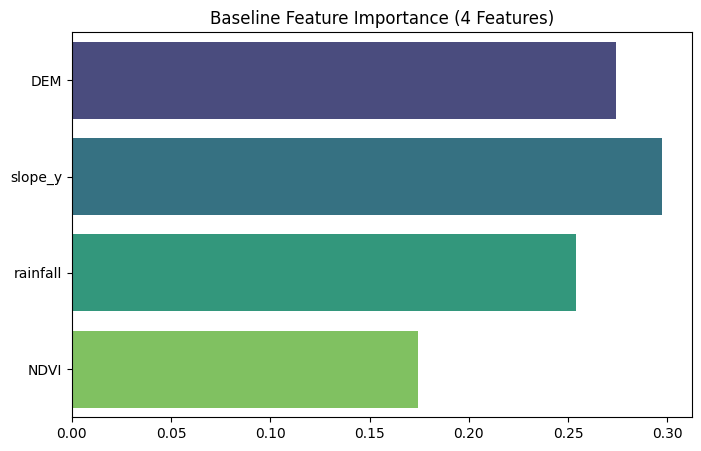

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

#Define Features and Target
feature_cols = ['DEM', 'slope_y', 'rainfall', 'NDVI']
X = df_NDVI[feature_cols]
y = df_NDVI['hazard label']

#Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Train
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
print("--- BASELINE CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred))

# Feature Importance
importances = rf.feature_importances_
plt.figure(figsize=(8, 5))
sns.barplot(x=importances, y=feature_cols, palette='viridis')
plt.title("Baseline Feature Importance (4 Features)")
plt.show()#it is seen in output that accuracy is great for baseline model, and the hazard recal and are extremely good, and is best overall

In [20]:
import folium

# Using the 4-feature dataset
df_map_final = df_NDVI.copy()

# Predict using the stable 4-feature model (rf)
feature_cols = ['DEM', 'slope_y', 'rainfall', 'NDVI']
X_map = df_map_final[feature_cols]
df_map_final['Prediction'] = rf.predict(X_map)

# Creating the map
m_final = folium.Map(location=[25.0, 95.0], zoom_start=4, tiles='Esri.WorldImagery')

# Plotting the points
for _, row in df_map_final.iterrows():
    color = 'red' if row['Prediction'] == 1 else 'green'

    popup_text = f"""
    <b>Prediction:</b> {'HAZARD' if row['Prediction'] == 1 else 'SAFE'}<br>
    <b>Actual Label:</b> {row['hazard label']}<br>
    <b>Slope:</b> {row['slope_y']:.2f}°<br>
    <b>Rainfall:</b> {row['rainfall']:.2f} mm<br>
    <b>NDVI:</b> {row['NDVI']:.2f}
    """

    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        color=color,
        fill=True,
        fill_color=color,
        popup=folium.Popup(popup_text, max_width=200),
        fill_opacity=0.7
    ).add_to(m_final)

# Save
m_final.save("final_static_map.html")
print("Final Static Map saved as 'final_static_map.html'")
m_final#static previous years based ai model heatmap

Output hidden; open in https://colab.research.google.com to view.

In [51]:
#checking if adding soil feature increases
import ee

# Load OpenLandMap Soil Texture (USDA classification)
soil = ee.Image("OpenLandMap/SOL/SOL_TEXTURE-CLASS_USDA-TT_M/v02")
# We want the surface layer (0-30cm), usually band 'b0'
soil_texture = soil.select('b0').rename('soil_type')

# Add it to existing stack
full_feature_stack_v2 = terrain_stack.addBands([
    rainfall.setDefaultProjection(dem.projection()),
    ndvi.setDefaultProjection(dem.projection()),
    soil_texture.setDefaultProjection(dem.projection())
])

#Sample the points
features_fc = ee.FeatureCollection(ee_features)
sampled_data_v2 = full_feature_stack_v2.sampleRegions(
    collection=features_fc,
    scale=30,
    geometries=False
)

#Export to Google Drive
task = ee.batch.Export.table.toDrive(
    collection=sampled_data_v2,
    description='Landslide_Features_Soil',
    folder='Disaster Management',
    fileNamePrefix='landslide_data_soil_',
    fileFormat='CSV'
)
task.start()
print("Export started! Check your Google Drive in a few minutes.")

Export started! Check your Google Drive in a few minutes.


V2 dataset shape: (1784, 13)
--- VERSION 2.0 (WITH SOIL) CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.79      0.69      0.74        90
           1       0.90      0.94      0.92       267

    accuracy                           0.88       357
   macro avg       0.85      0.81      0.83       357
weighted avg       0.87      0.88      0.87       357



/tmp/ipykernel_4202/1047061756.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances_v2, y=feature_cols_v2, palette='magma')


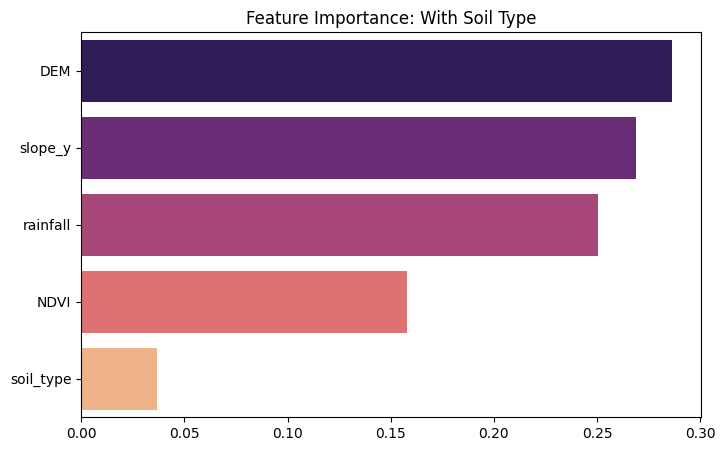

In [52]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Load the new CSV
file_path = '/content/drive/MyDrive/Disaster management/landslide_data_soil_.csv'
df_gee_soil = pd.read_csv(file_path)

# 2. Merge with original table
df_final_v2 = df_cleaned_physics.merge(df_gee_soil, left_index=True, right_on='row_id')

# Drop old slope_x if it exists
if 'slope_x' in df_final_v2.columns:
    df_final_v2 = df_final_v2.drop(columns=['slope_x'])

# Drop nulls
cols_to_dropna = ['DEM', 'slope_y', 'rainfall', 'NDVI', 'soil_type']
if 'DEM_y' in df_final_v2.columns:
    cols_to_dropna[0] = 'DEM_y'
df_final_v2 = df_final_v2.dropna(subset=cols_to_dropna)

print(f"V2 dataset shape: {df_final_v2.shape}")

# Train Version 2.0
feature_cols_v2 = ['DEM', 'slope_y', 'rainfall', 'NDVI', 'soil_type']
X_v2 = df_final_v2[feature_cols_v2]
y_v2 = df_final_v2['hazard label'] # Change if your column name is different

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(X_v2, y_v2, test_size=0.2, random_state=42, stratify=y_v2)

rf_v2 = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_v2.fit(X_train_v2, y_train_v2)

y_pred_v2 = rf_v2.predict(X_test_v2)

print("--- VERSION 2.0 (WITH SOIL) CLASSIFICATION REPORT ---")
print(classification_report(y_test_v2, y_pred_v2))

# Feature Importance V2
importances_v2 = rf_v2.feature_importances_
plt.figure(figsize=(8, 5))
sns.barplot(x=importances_v2, y=feature_cols_v2, palette='magma')
plt.title("Feature Importance: With Soil Type")
plt.show() #this is significantly better than the previous model upon first run, but the second training phase it has done worse than the first model,  due to varinace and ovefitting..

In [ ]:
#now presentation using follium of how the ai thinks (basically heatmap)
import folium
from folium.plugins import MarkerCluster
import pandas as pd
# We set a low zoom level so we can see both countries
m = folium.Map(location=[25.0, 95.0], zoom_start=4, tiles='Esri.WorldStreetMap', attr="Esri")

# Sample the dataset to make the map run faster
df_map = df_final_v2.sample(450, random_state=42).copy()

# Loop through data and plot the points
for index, row in df_map.iterrows():
    # Ensure we grab the right lat/lon columns.
    lat = row['latitude']
    lon = row['longitude']

    # Define color based on label
    if row['hazard label'] == 1:
        color = 'red'
        label_text = 'HAZARD'
    else:
        color = 'green'
        label_text = 'SAFE'

    # Create a popup showing the features
    popup_text = f"""
    <b>Status:</b> {label_text}<br>
    <b>Elevation:</b> {row.get('DEM', row.get('DEM_y', 'N/A'))} m<br>
    <b>Slope:</b> {row.get('slope_y', 'N/A'):.2f}°<br>
    <b>Rainfall:</b> {row.get('rainfall', 'N/A'):.2f} mm<br>
    <b>Soil Type:</b> {row.get('soil_type', 'N/A')}
    """

    # Add the point to the map
    folium.CircleMarker(
        location=[lat, lon],
        radius=3, # Size of the dot
        popup=folium.Popup(popup_text, max_width=200),
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7
    ).add_to(m)

# Display the map
m
#the ai trained is based on previous year, and is static

In [ ]:
#was going to use gpm but because of it being heavy for the 2 countires and is timing out, we are going wiht a workaround
#(live model)

In [42]:
import ee
from datetime import datetime, timedelta, timezone

# Define region
india_box = ee.Geometry.Rectangle([68.0, 8.0, 97.0, 35.0])
japan_box = ee.Geometry.Rectangle([129.0, 30.0, 146.0, 46.0])
region = india_box.union(japan_box)

# Get Live Rain
today = datetime.now(timezone.utc)
last_week = today - timedelta(days=7)
live_gpm = ee.ImageCollection('NASA/GPM_L3/IMERG_V07') \
    .filterDate(last_week.strftime('%Y-%m-%d'), today.strftime('%Y-%m-%d')) \
    .select('precipitation')

live_rainfall = live_gpm.sum().clip(region).rename('rainfall')

# Create the Stack
live_stack = terrain_stack.addBands([
    live_rainfall.setDefaultProjection(dem.projection()),
    ndvi.setDefaultProjection(dem.projection())
])

# Generate 5000 Points and Sample
random_points = ee.FeatureCollection.randomPoints(region, points=5000, seed=42)
sampled_grid = live_stack.sampleRegions(
    collection=random_points,
    scale=1000,
    geometries=True
)

# Export
task = ee.batch.Export.table.toDrive(
    collection=sampled_grid,
    description='Live_Grid_Python',
    folder='Disaster management',
    fileNamePrefix='live_grid_for_python_',
    fileFormat='CSV'
)
task.start()
print("Export started! Check Drive in 1 minute.")

Export started! Check Drive in 1 minute.


In [44]:
import joblib
joblib.dump(rf, '/content/drive/MyDrive/Disaster management/landslide_model.pkl')
print("Model saved as 'landslide_model.pkl' to your Drive!")

Model saved as 'landslide_model.pkl' to your Drive!


In [54]:
import pandas as pd
import folium
import json
# Load the Live CSV
df_live = pd.read_csv('/content/drive/MyDrive/Disaster management/live_grid_for_python_.csv')

# Extract Lat/Lon
def extract_coords(geo_data):
    # If it's already a dictionary (from JSON parsing)
    if isinstance(geo_data, dict):
        return pd.Series([geo_data['coordinates'][1], geo_data['coordinates'][0]])

    # If it's a string
    if isinstance(geo_data, str):
        # Case 1: JSON string format
        if geo_data.startswith('{'):
            try:
                data = json.loads(geo_data)
                return pd.Series([data['coordinates'][1], data['coordinates'][0]])
            except:
                pass
        # Case 2: WKT string format "POINT (lon lat)"
        if 'POINT' in geo_data:
            try:
                coords = geo_data.replace('POINT (', '').replace(')', '').split(' ')
                return pd.Series([float(coords[1]), float(coords[0])])
            except:
                pass

    # If it fails, return NaN
    return pd.Series([None, None])

# Apply the parser
df_live[['latitude', 'longitude']] = df_live['.geo'].apply(extract_coords)

# Drop any rows where parsing failed
df_live = df_live.dropna(subset=['latitude', 'longitude'])
print(f"Successfully extracted coordinates for {len(df_live)} points.")
print(df_live[['latitude', 'longitude']].head())

#Rename 'slope' to 'slope_y' to match the AI fitting done
if 'slope' in df_live.columns:
    df_live = df_live.rename(columns={'slope': 'slope_y'})
    print("Renamed 'slope' to 'slope_y'")
elif 'slope_x' in df_live.columns:
    df_live = df_live.rename(columns={'slope_x': 'slope_y'})
    print("Renamed 'slope_x' to 'slope_y'")
# Predict using Python model (rf)
features = ['DEM', 'slope_y', 'rainfall', 'NDVI']
X_live = df_live[features].dropna()
df_live = df_live.loc[X_live.index]
df_live['Prediction'] = rf.predict(X_live)


# Map
m = folium.Map(location=[25.0, 95.0], zoom_start=4, tiles='Esri.WorldImagery')

for _, row in df_live.iterrows():
    color = 'red' if row['Prediction'] == 1 else 'green'

    # Format the text nicely
    tooltip_text = (
        f"<b>{'HAZARD' if row['Prediction'] == 1 else 'SAFE'}</b><br>"
        f"Slope: {row['slope_y']:.2f}°<br>"
        f"Rainfall: {row['rainfall']:.2f} mm<br>"
        f"NDVI: {row['NDVI']:.2f}"
    )

    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3, # Small size
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7,
        tooltip=folium.Tooltip(tooltip_text), # Shows on hover
        popup=folium.Popup(tooltip_text, max_width=250) # Shows on click!
    ).add_to(m)

# Save it
m.save("live_risk_map_python_v3.html")
print("Small circles with hover tooltips generated!")
m

Output hidden; open in https://colab.research.google.com to view.

In [55]:
import shutil
shutil.copy("live_risk_map_python_v3.html", "/content/drive/MyDrive/Disaster management/live_risk_map_python_v3.html")

print("File saved to your Google Drive 'Disaster management' folder!")

File saved to your Google Drive 'Disaster management' folder!
